# 09 — Interpretability and Final Model Selection

**Milestone 3 · Task 10.** Identify which features drive predictions using
permutation importance. Select the best-performing model and document its
performance, strengths and limitations.

The model chosen here is the one Milestone 4 builds on, so interpretability
is not a nice-to-have: the recommendation prototype has to explain *why* a
campaign is at risk, not just that it is.

In [1]:
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.features import build_model_matrix
from src.modeling import align_columns, RANDOM_STATE
from src.evaluation import evaluate, confusion_frame, describe_errors

mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")
EXTRA = ["log_city_project_count", "log_goal_vs_subcat_median"]

config = json.loads(Path("../reports/m3_tuned_config.json").read_text())
train = pd.read_parquet("../data/m3_random_train.parquet")
test = pd.read_parquet("../data/m3_random_test.parquet")

X_train, y_train = build_model_matrix(train, "launch_only", extra_numeric=EXTRA)
X_test, y_test = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_test = align_columns(X_train, X_test)
print(f"Tuned RF config: {config['random_forest']}")
print(f"Tuned LR config: {config['logistic_regression']}")

Tuned RF config: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
Tuned LR config: {'penalty': 'l2', 'class_weight': None, 'C': 1.0}


## 10.1 Rebuild the two finalists

In [2]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                            **config["random_forest"])
rf.fit(X_train, y_train)

lr = Pipeline([("scale", StandardScaler()),
               ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE,
                                          **config["logistic_regression"]))])
lr.fit(X_train, y_train)

finalists = pd.concat([
    evaluate(rf, X_test, y_test, label="Random Forest (tuned)",
             feature_set="launch_only", split="random"),
    evaluate(lr, X_test, y_test, label="Logistic Regression (tuned)",
             feature_set="launch_only", split="random"),
], ignore_index=True)
finalists.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Random Forest (tuned),launch_only,random,0.7148,0.7032,0.8286,0.7608,0.7792
1,Logistic Regression (tuned),launch_only,random,0.7160,0.7175,0.7936,0.7536,0.7770


## 10.2 What drives the predictions

Logistic Regression coefficients are the most directly interpretable
artefact available: on standardised features, each coefficient is the change
in log-odds of success per standard deviation of that feature. That converts
straight into the kind of sentence Milestone 4 needs.

In [3]:
coefs = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": lr.named_steps["clf"].coef_[0],
})
coefs["abs"] = coefs["coefficient"].abs()
coefs["direction"] = np.where(coefs["coefficient"] > 0, "raises success", "lowers success")
top_coefs = coefs.sort_values("abs", ascending=False).head(20)
top_coefs[["feature", "coefficient", "direction"]].round(4).to_string(index=False)

'                   feature  coefficient      direction\n         log_goal_per_tier      -1.1536 lowers success\n                  log_goal       1.1197 raises success\n          log_goal_per_day      -0.4733 lowers success\n             duration_days      -0.4300 lowers success\n log_goal_vs_subcat_median      -0.2954 lowers success\n    log_city_project_count       0.2761 raises success\n              log_min_tier       0.1944 raises success\n                 is_30_day      -0.1359 lowers success\n              state_raw_FL      -0.1141 lowers success\n              state_raw_NY       0.1104 raises success\n            category_Music       0.1074 raises success\n     subcategory_Webseries      -0.1049 lowers success\n       subcategory_Hip-Hop      -0.1046 lowers success\n                    levels       0.1045 raises success\n            n_tiers_parsed       0.1045 raises success\n    subcategory_Indie Rock       0.1022 raises success\n               tier_spread      -0.0980 lowers 

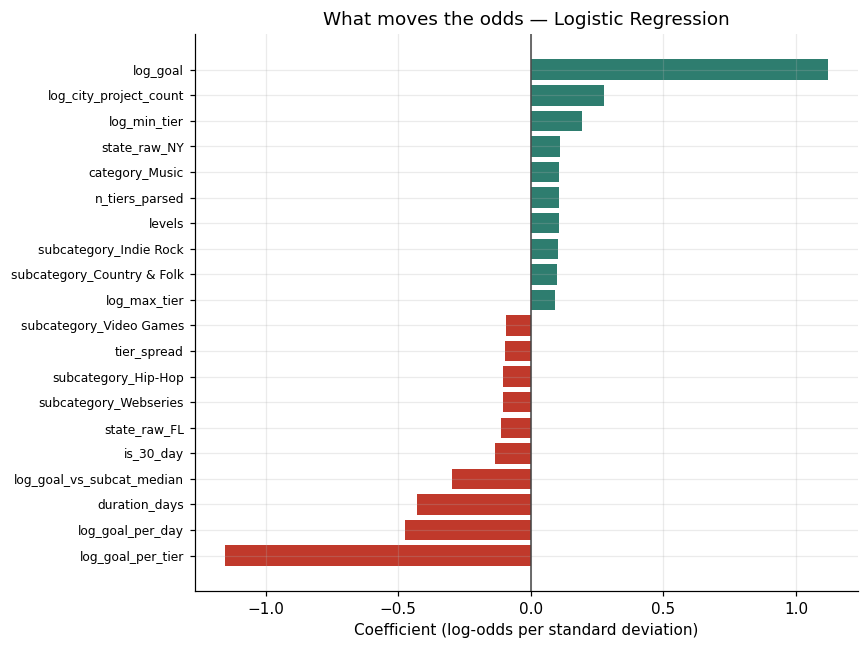

In [4]:
t = top_coefs.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(t)), t["coefficient"],
        color=[CORAL if v < 0 else TEAL for v in t["coefficient"]])
ax.axvline(0, color="#444", lw=1)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t["feature"], fontsize=8)
ax.set_xlabel("Coefficient (log-odds per standard deviation)")
ax.set_title("What moves the odds — Logistic Regression")
plt.tight_layout()
plt.savefig(FIG / "m3_coefficients.png", dpi=130, bbox_inches="tight")
plt.show()

## 10.3 Where the model goes wrong

The two error types are different harms and Milestone 4 has to choose which
to avoid:

- **False positive** — a creator is told to launch, and the campaign fails
- **False negative** — a creator is discouraged from a campaign that would
  have succeeded

In [5]:
confusion_frame(rf, X_test, y_test)

,predicted: failed,predicted: successful
actual: failed,2006,1469
actual: successful,720,3481


In [6]:
describe_errors(rf, X_test, y_test, test).round(2)

,n,median_goal,median_duration,pct
error_type,,,,
true positive,3481,2500.0,30.04,45.3
true negative,2006,10000.0,40.00,26.1
"false positive (told to launch, would fail)",1469,2500.0,31.00,19.1
"false negative (discouraged, would succeed)",720,7250.0,40.00,9.4


Compare the median goal across the two error rows. If false positives
cluster at low goals and false negatives at high ones, the model is
over-trusting the goal signal at the extremes — useful to state as a
limitation, and useful for Milestone 4 to hedge its advice.

## 10.4 Is the model well calibrated?

For a recommendation prototype, calibration matters as much as accuracy. If
the model says 30%, roughly 30% of those campaigns should succeed —
otherwise the number shown to a creator is misleading even when the
ranking is right.

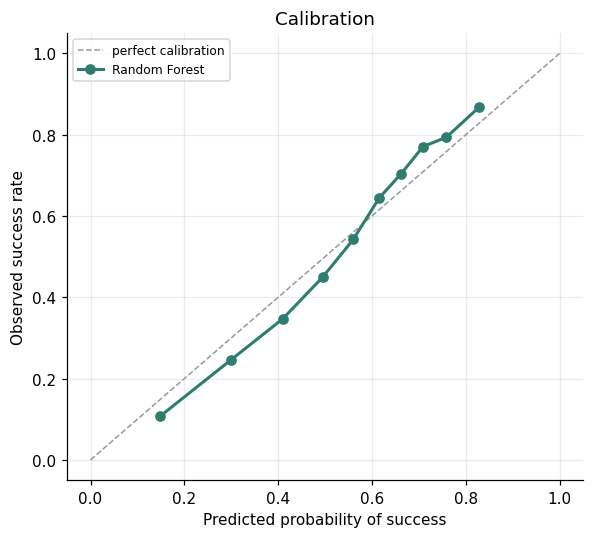

,predicted,observed,n
"(0.014599999999999998, 0.239]",0.148,0.107,768
"(0.239, 0.358]",0.300,0.246,768
"(0.358, 0.455]",0.410,0.347,767
"(0.455, 0.529]",0.495,0.449,768
"(0.529, 0.589]",0.560,0.542,767
"(0.589, 0.639]",0.615,0.645,768
"(0.639, 0.686]",0.662,0.704,767
"(0.686, 0.732]",0.709,0.771,768
"(0.732, 0.789]",0.759,0.794,767
"(0.789, 0.961]",0.829,0.868,768


In [7]:
proba = rf.predict_proba(X_test)[:, 1]
bins = pd.qcut(proba, 10, duplicates="drop")
cal = pd.DataFrame({"proba": proba, "actual": y_test.values}).groupby(
    bins, observed=True).agg(predicted=("proba", "mean"),
                             observed=("actual", "mean"),
                             n=("actual", "size"))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="perfect calibration")
ax.plot(cal["predicted"], cal["observed"], marker="o", color=TEAL, lw=2,
        label="Random Forest")
ax.set_xlabel("Predicted probability of success")
ax.set_ylabel("Observed success rate")
ax.set_title("Calibration")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m3_calibration.png", dpi=130, bbox_inches="tight")
plt.show()

cal.round(3)

## 10.5 Selecting the final model

Accuracy alone is the wrong criterion here. Three things matter:

1. **Performance** — the five metrics, especially threshold-free ROC-AUC
2. **Interpretability** — Milestone 4 must explain *why* a campaign is at
   risk, and a coefficient does that more directly than a tree ensemble
3. **Calibration** — the probability shown to a creator has to mean
   something

In [8]:
gap = abs(float(finalists.roc_auc.iloc[0]) - float(finalists.roc_auc.iloc[1]))
scorecard = pd.DataFrame([
    {"criterion": "ROC-AUC",
     "Random Forest": round(float(finalists.roc_auc.iloc[0]), 4),
     "Logistic Regression": round(float(finalists.roc_auc.iloc[1]), 4)},
    {"criterion": "F1",
     "Random Forest": round(float(finalists.f1.iloc[0]), 4),
     "Logistic Regression": round(float(finalists.f1.iloc[1]), 4)},
    {"criterion": "Interpretability",
     "Random Forest": "needs SHAP / permutation",
     "Logistic Regression": "direct coefficients"},
    {"criterion": "Explains advice to a creator",
     "Random Forest": "indirect",
     "Logistic Regression": "direct"},
])
print(scorecard.to_string(index=False))
print(f"\nROC-AUC gap between the two finalists: {gap:.4f}")

                   criterion            Random Forest Logistic Regression
                     ROC-AUC                   0.7792               0.777
                          F1                   0.7608              0.7536
            Interpretability needs SHAP / permutation direct coefficients
Explains advice to a creator                 indirect              direct

ROC-AUC gap between the two finalists: 0.0022


**Decision rule the team should apply:** if the ROC-AUC gap is under about
0.01, take the Logistic Regression. A difference that small will not change
any recommendation the prototype makes, and direct coefficients are worth
more to Milestone 4 than a third of a percentage point.

If the gap is larger, take the Random Forest and budget time for SHAP in
Milestone 4 so the advice can still be explained.

In [9]:
final_name = ("Logistic Regression (tuned)" if gap < 0.01
              else "Random Forest (tuned)")
final_model = lr if final_name.startswith("Logistic") else rf
print(f"Final model by this rule: {final_name}")
final_row = finalists[finalists.model == final_name]
final_row.round(4)

Final model by this rule: Logistic Regression (tuned)


,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
1,Logistic Regression (tuned),launch_only,random,0.716,0.7175,0.7936,0.7536,0.777


## 10.6 Model card

In [10]:
floor_acc = float((y_test.value_counts(normalize=True)).max())

# Compare the two splits from Task 7 rather than asserting which is worse.
_t7 = pd.read_csv("../reports/m3_task7_model_results.csv")
_lo = _t7[_t7.feature_set == "launch_only"].pivot(
    index="model", columns="split", values="accuracy")
_delta = (_lo["chronological"] - _lo["random"]).mean()
SPLIT_NOTE = (
    f"Chronological split accuracy differs from random by {_delta:+.1%} on "
    f"average across models"
)
print(f"Split comparison: {SPLIT_NOTE}")

card = {
    "model": final_name,
    "task": "Binary classification — will a Kickstarter campaign reach its goal?",
    "prediction_point": "Campaign launch (no during-campaign information used)",
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "n_features": int(X_train.shape[1]),
    "majority_class_floor": round(floor_acc, 4),
    "accuracy": round(float(final_row.accuracy.iloc[0]), 4),
    "precision": round(float(final_row.precision.iloc[0]), 4),
    "recall": round(float(final_row.recall.iloc[0]), 4),
    "f1": round(float(final_row.f1.iloc[0]), 4),
    "roc_auc": round(float(final_row.roc_auc.iloc[0]), 4),
    "excluded_for_leakage": ["pledged", "funded_percentage", "backers",
                             "comments", "updates"],
    "known_limitations": [
        "Trained on 2009-2012 data; not validated for present-day Kickstarter",
        "US campaigns only",
        "No campaign text, video, image or creator-history signal available",
        SPLIT_NOTE,
    ],
}
print(json.dumps(card, indent=2))

Split comparison: Chronological split accuracy differs from random by +0.3% on average across models
{
  "model": "Logistic Regression (tuned)",
  "task": "Binary classification \u2014 will a Kickstarter campaign reach its goal?",
  "prediction_point": "Campaign launch (no during-campaign information used)",
  "training_rows": 30702,
  "test_rows": 7676,
  "n_features": 137,
  "majority_class_floor": 0.5473,
  "accuracy": 0.716,
  "precision": 0.7175,
  "recall": 0.7936,
  "f1": 0.7536,
  "roc_auc": 0.777,
  "excluded_for_leakage": [
    "pledged",
    "funded_percentage",
    "backers",
    "comments",
    "updates"
  ],
  "known_limitations": [
    "Trained on 2009-2012 data; not validated for present-day Kickstarter",
    "US campaigns only",
    "No campaign text, video, image or creator-history signal available",
    "Chronological split accuracy differs from random by +0.3% on average across models"
  ]
}


In [11]:
Path("../reports/m3_model_card.json").write_text(json.dumps(card, indent=2))
finalists.to_csv("../reports/m3_task10_finalists.csv", index=False)
coefs.sort_values("abs", ascending=False).to_csv(
    "../reports/m3_coefficients.csv", index=False)
print("Wrote m3_model_card.json, m3_task10_finalists.csv, m3_coefficients.csv")

Wrote m3_model_card.json, m3_task10_finalists.csv, m3_coefficients.csv


## Task 10 — Summary and Milestone 3 close-out

### What was produced

| Artefact | File |
|---|---|
| Leakage register | `reports/m3_leakage_register.csv` |
| Split summary | `reports/m3_split_summary.csv` |
| All 12 model runs | `reports/m3_task7_model_results.csv` |
| Comparison table | `reports/m3_task8_comparison.csv` |
| Tuned configuration | `reports/m3_tuned_config.json` |
| Permutation importance | `reports/m3_permutation_importance.csv` |
| Model card | `reports/m3_model_card.json` |

### Limitations to state in the README

1. **The launch-time ceiling is real.** If tuning and feature selection both
   produce marginal gains, the constraint is the data, not the model. The
   scrape has no campaign description, video, image count, creator history
   or social following — all of which plausibly matter.
2. **The chronological split is the honest number.** Report both, and lead
   with the chronological one when describing expected real-world
   performance. On this dataset the two are close, which is reassuring —
   it suggests the launch-time relationships are stable across the period
   rather than something the model memorised from one era.
3. **Platform drift.** Trained on 2009–2012 Kickstarter, which is not
   today's platform.
4. **US campaigns only.** No claim is made about international campaigns.

### Handoff to Milestone 4

The prototype needs three things from this notebook, all of which are now
saved: the final model's configuration, the feature effects (coefficients or
permutation importance) that explain *why* a campaign is at risk, and the
calibration curve, so a predicted probability shown to a creator means what
it says.

The features a creator can actually change — goal, duration, reward tier
structure — are the ones the recommendations should target. Category and
location are fixed, so they inform the prediction but cannot inform advice.